In [91]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf
from keras.layers import Dense

In [92]:
data = tf.keras.datasets.fashion_mnist.load_data()
print(type(data))
print(len(data))

<class 'tuple'>
2


In [93]:
print(type(data[0]))
print(type(data[1]))
print(len(data[0]))
print(len(data[1]))

<class 'tuple'>
<class 'tuple'>
2
2


In [94]:
(x_train_full, y_train_full) , (x_test, y_test) = data
print(f"x_train: {x_train_full.shape}, y_train:{y_train_full.shape}, x_test:{x_test.shape}, y_test:{y_test.shape}")

x_train: (60000, 28, 28), y_train:(60000,), x_test:(10000, 28, 28), y_test:(10000,)


In [95]:
print(type(x_train_full))

<class 'numpy.ndarray'>


In [96]:
print(x_train_full.max())
print(x_train_full.min())
print(x_train_full.dtype)

255
0
uint8


#### Normalized

In [97]:
MAX_PIXEL_VALUE = 255.0
x_train_full = x_train_full.astype("float32") / MAX_PIXEL_VALUE
x_train = x_test.astype("float32") / MAX_PIXEL_VALUE

#### Train\ Validation \ Test

In [98]:
TRAIN_SIZE = 30_000
x_val = x_train_full[TRAIN_SIZE:]
y_val = y_train_full[TRAIN_SIZE:]

x_train = x_train_full[:TRAIN_SIZE]
y_train = y_train_full[:TRAIN_SIZE]

In [99]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]

In [100]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (30000, 28, 28), val: (30000, 28, 28), test: (10000, 28, 28), class: 10


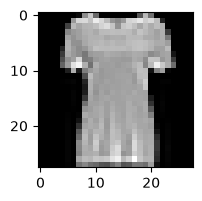

In [101]:
plt.figure(figsize=(2,3))
plt.imshow(x_train[10], cmap="gray")
plt.show()

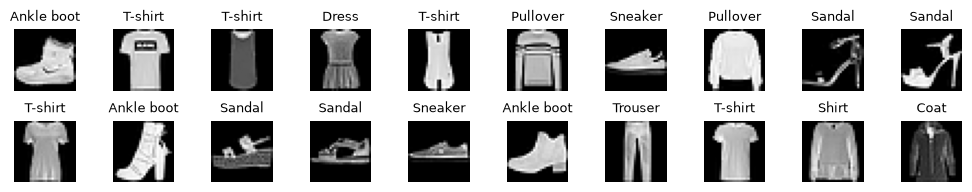

In [102]:
fig, axes = plt.subplots(2, 10, figsize=(10, 2))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap= "gray")
    ax.set_title(CLASS_NAMES[label], fontsize= 9)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Early stopping

In [103]:
dense_model1 = keras.Sequential()
dense_model1.add(keras.layers.Input(shape=(28, 28)))
dense_model1.add(keras.layers.Flatten())
dense_model1.add(Dense(64, activation="relu"))
dense_model1.add(Dense(128, activation="relu"))
dense_model1.add(Dense(64, activation="relu"))
dense_model1.add(Dense(32, activation="softmax"))


In [105]:
dense_model1.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)

In [106]:
dense_model2 = keras.Sequential()
dense_model2.add(keras.layers.Input(shape=(28, 28)))
dense_model2.add(keras.layers.Flatten())
dense_model2.add(Dense(32, activation="relu"))
dense_model2.add(Dense(128, activation="relu"))
dense_model2.add(Dense(32, activation="relu"))
dense_model2.add(Dense(16, activation="softmax"))

In [107]:
dense_model2.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
    )

In [108]:
result1 = dense_model1.fit(
    x_train, y_train, 
    validation_split=0.2, epochs=400, batch_size=32)

Epoch 1/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7654 - loss: 0.6635 - val_accuracy: 0.8393 - val_loss: 0.4696
Epoch 2/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8381 - loss: 0.4444 - val_accuracy: 0.8477 - val_loss: 0.4130
Epoch 3/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8523 - loss: 0.4007 - val_accuracy: 0.8632 - val_loss: 0.3905
Epoch 4/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8635 - loss: 0.3681 - val_accuracy: 0.8283 - val_loss: 0.4687
Epoch 5/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8721 - loss: 0.3433 - val_accuracy: 0.8717 - val_loss: 0.3568
Epoch 6/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8801 - loss: 0.3217 - val_accuracy: 0.8695 - val_loss: 0.3661
Epoch 7/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8857 - loss: 0.3029 - val_accuracy: 0.8612 - val_loss: 0.3886
Epoch 8/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8927 - loss: 0.2916 - val_accu

In [109]:
result2 = dense_model2.fit(
    x_train, y_train, 
    validation_split=0.2, epochs=400, batch_size=32)

Epoch 1/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7684 - loss: 0.6682 - val_accuracy: 0.8315 - val_loss: 0.4792
Epoch 2/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8378 - loss: 0.4524 - val_accuracy: 0.8390 - val_loss: 0.4538
Epoch 3/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8536 - loss: 0.4046 - val_accuracy: 0.8497 - val_loss: 0.4202
Epoch 4/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8647 - loss: 0.3698 - val_accuracy: 0.8612 - val_loss: 0.3903
Epoch 5/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8691 - loss: 0.3568 - val_accuracy: 0.8645 - val_loss: 0.3759
Epoch 6/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8738 - loss: 0.3373 - val_accuracy: 0.8658 - val_loss: 0.3868
Epoch 7/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8805 - loss: 0.3200 - val_accuracy: 0.8625 - val_loss: 0.3896
Epoch 8/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8845 - loss: 0.3088 - val_accu

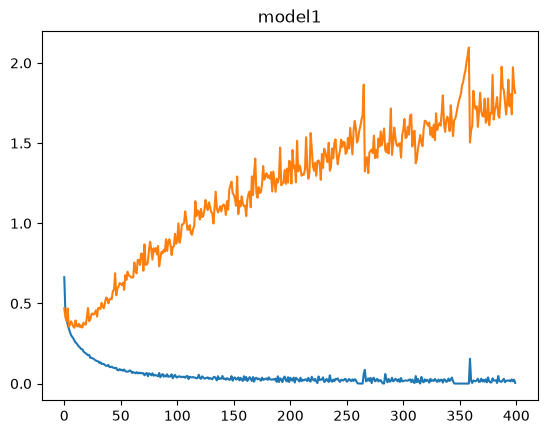

In [111]:
plt.plot(result1.history["loss"], label="train loss")
plt.plot(result1.history["val_loss"], label="validation loss")
plt.title("model1")
plt.show()

In [117]:
early_stop1 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=120, restore_best_weights=True)
result1 = dense_model1.fit(x_train, y_train, validation_split=0.2, epochs=400, batch_size=32, callbacks=[early_stop1])

Epoch 1/400


750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9760 - loss: 0.1138 - val_accuracy: 0.8768 - val_loss: 1.7604
Epoch 2/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9945 - loss: 0.0197 - val_accuracy: 0.8798 - val_loss: 1.6681
Epoch 3/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9942 - loss: 0.0201 - val_accuracy: 0.8802 - val_loss: 1.6155
Epoch 4/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9935 - loss: 0.0304 - val_accuracy: 0.8777 - val_loss: 1.5998
Epoch 5/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9974 - loss: 0.0083 - val_accuracy: 0.8780 - val_loss: 1.7439
Epoch 6/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9940 - loss: 0.0212 - val_accuracy: 0.8802 - val_loss: 1.7570
Epoch 7/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9940 - loss: 0.0215 - val_accuracy: 0.8733 - val_loss: 1.8293
Epoch 8/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9962 - loss: 0.0129 - val_accuracy: 0.8805

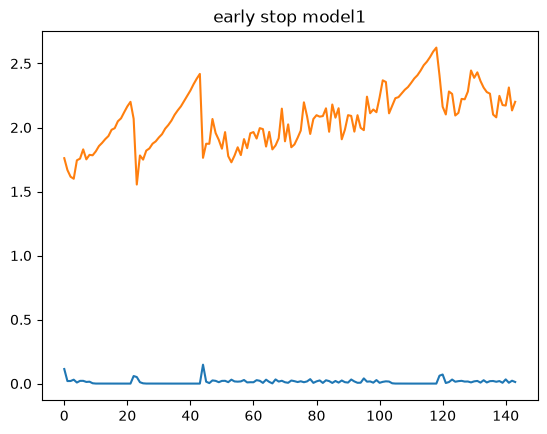

In [118]:
plt.plot(result1.history["loss"], label="train loss model1")
plt.plot(result1.history["val_loss"], label="validation loss model1")
plt.title("early stop model1")
plt.show()

In [119]:
early_stop2 = keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)
result1 = dense_model1.fit(x_train, y_train, validation_split=0.2, epochs=400, batch_size=32, callbacks=[early_stop2])

Epoch 1/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9953 - loss: 0.0159 - val_accuracy: 0.8790 - val_loss: 1.8300
Epoch 2/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9939 - loss: 0.0216 - val_accuracy: 0.8787 - val_loss: 1.7331
Epoch 3/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9970 - loss: 0.0080 - val_accuracy: 0.8817 - val_loss: 1.7405
Epoch 4/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9915 - loss: 0.0330 - val_accuracy: 0.8773 - val_loss: 1.8959
Epoch 5/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9958 - loss: 0.0167 - val_accuracy: 0.8738 - val_loss: 1.7774
Epoch 6/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9927 - loss: 0.0250 - val_accuracy: 0.8800 - val_loss: 1.7787
Epoch 7/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9969 - loss: 0.0159 - val_accuracy: 0.8715 - val_loss: 1.8328
Epoch 8/400
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9949 - loss: 0.0161 - val_accu

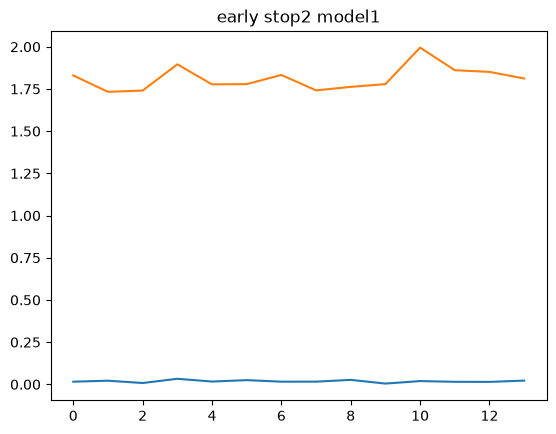

In [120]:
plt.plot(result1.history["loss"], label="train loss model1")
plt.plot(result1.history["val_loss"], label="validation loss model1")
plt.title("early stop2 model1")
plt.show()